In [30]:
options(warn = -1)
suppressMessages(require(Seurat))
suppressMessages(require(ggplot2))
suppressMessages(require(dplyr))
suppressMessages(require(reticulate))
suppressMessages(require(stringr))
suppressMessages(require(ggpubr))
suppressMessages(require(tidydr))
suppressMessages(require(CellTrek))
suppressMessages(require(CARD))
devtools::load_all('../Cell2Spatial/')

ℹ Loading Cell2Spatial


In [31]:
source('modules/globalParams.R')
source('modules/utils.R')
source('modules/vis.R')
source('modules/reformatProjRes.R')

In [32]:
out.figs.dir <- '../2.results/BRCA.2/figs'
out.data.dir <- '../2.results/BRCA.2/data'

In [33]:
dir.create(out.figs.dir, showWarnings = FALSE, recursive = TRUE)
dir.create(out.data.dir, showWarnings = FALSE, recursive = TRUE)

In [34]:
MTH_COLOR <- c(
    'Reference'    = 'grey',
    'Cell2Spatial' = '#F7B263',
    'CytoSPACE' = '#D6AA8E',
    'CellTrek' = '#99C0CC',
    'Tangram' = 'lightgreen',
    'Seurat' = '#CC00FF'
)

### Loading kidney ST and SC datasets 

In [214]:
brain.st <- readRDS('../0.data/BRCA/BRCA_SP2.RDS')

In [215]:
brain.sc <- readRDS('../0.data/BRCA/BRCA_SC.RDS')

In [216]:
brain.st <- brain.st %>% SCTransform(., verbose = FALSE, assay = 'Spatial') %>%
    RunPCA(verbose = FALSE) %>%
    RunUMAP(dims = 1 : 30, verbose = FALSE) %>%
    FindNeighbors(., dims = 1:30, verbose = FALSE) %>%
    FindClusters(., verbose = FALSE)

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



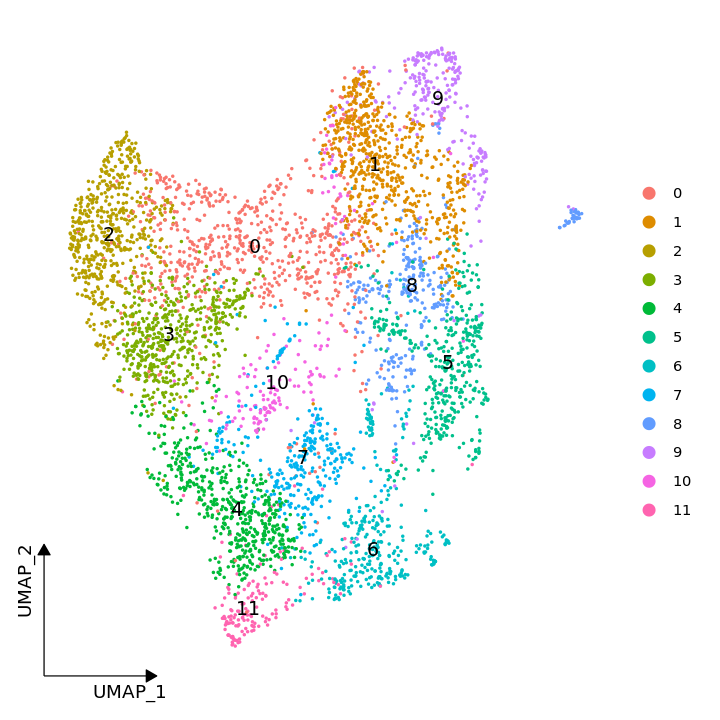

In [217]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(brain.st, reduction = "umap", label = TRUE) + theme_dr(xlength = 0.2, ylength = 0.2, arrow = grid::arrow(length = unit(0.1, "inches"), ends = 'last', type = "closed")) + theme(panel.grid = element_blank())
ggsave(file.path(out.figs.dir, 'BRCA.ST.cluster.UMAP.dimplot.pdf'), width = 6, height = 6)

In [344]:
dim(brain.st)

[1] 20002  4895

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


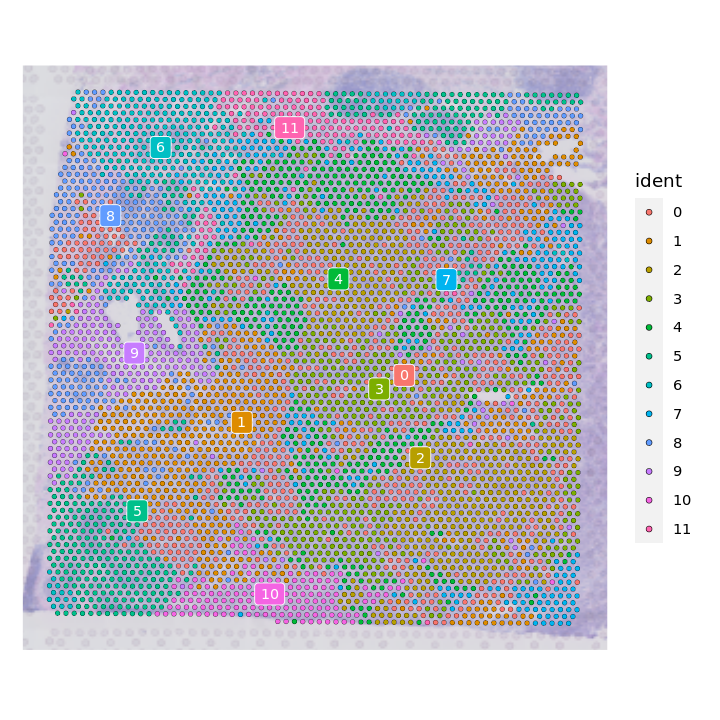

In [218]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialDimPlot(brain.st, label = TRUE, label.size = 3, image.alpha = 0.5)
ggsave(file.path(out.figs.dir, 'BRCA.ST.cluster.UMAP.spatial.pdf'), width = 6, height = 6)

In [219]:
f.ctypes <- levels(brain.st)
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(brain.st, idents = ct) %>% Cells
    SpatialPlot(brain.st, cells.highlight = h.cells) + NoLegend() + ggtitle(ct) 
})

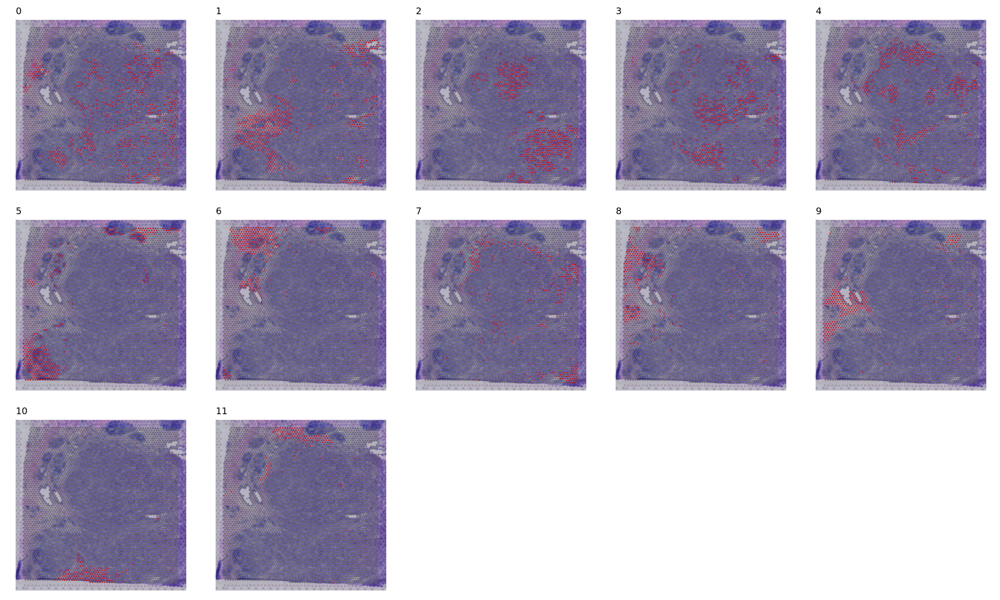

In [220]:
options(repr.plot.width = 20, repr.plot.height = 12)
ggarrange(plotlist = gps, nrow = 3, ncol = 5)

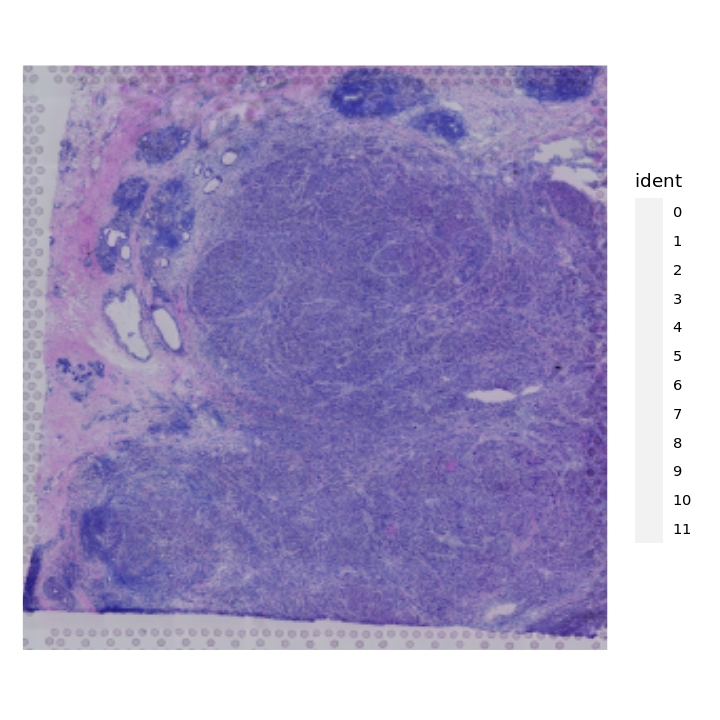

In [221]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialDimPlot(brain.st, label = FALSE, label.size = 3,, alpha = 0)
ggsave(file.path(out.figs.dir, 'BRCA.ST.Image.spatial.pdf'), width = 6, height = 6)

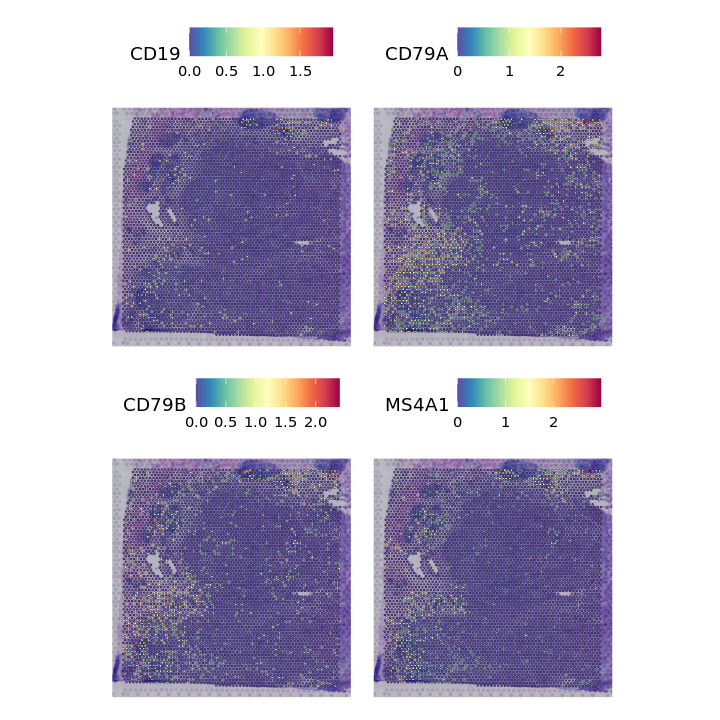

In [222]:
options(repr.plot.width = 6, repr.plot.height = 6)
SpatialFeaturePlot(brain.st, features = c('CD19', 'CD79A', 'CD79B', 'MS4A1'))

In [223]:
brain.sc@meta.data %>% head

,orig.ident,nCount_RNA,nFeature_RNA,X,percent.mito,subtype,celltype_subset,celltype_minor,celltype_major
,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
CID4471_CCGGTAGAGATTACCC,CID4471,4143,1760,CID4471_CCGGTAGAGATTACCC,7.289404,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID3921_GGCAATTGTGATGTGG,CID3921,20181,4146,CID3921_GGCAATTGTGATGTGG,6.516030,HER2+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID44041_GTCAAGTAGGGTGTTG,CID44041,1675,853,CID44041_GTCAAGTAGGGTGTTG,4.059701,TNBC,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID4530N_GCGCCAAGTCAGGACA,CID4530N,10408,3234,CID4530N_GCGCCAAGTCAGGACA,5.130669,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID4290A_GTCAAGTGTTAAGATG,CID4290A,2481,1240,CID4290A_GTCAAGTGTTAAGATG,9.633212,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial
CID4471_CCCAGTTGTTGCGCAC,CID4471,6254,2100,CID4471_CCCAGTTGTTGCGCAC,5.052766,ER+,Endothelial RGS5,Endothelial RGS5,Endothelial


In [224]:
Idents(brain.sc) <- brain.sc$celltype_major

In [225]:
options(future.globals.maxSize = 5000000 * 1024^2, future.seed = TRUE)

brain.sc <- SCTransform(brain.sc, ncells = 3000, verbose = FALSE) %>%
    RunPCA(verbose = FALSE) %>%
    RunUMAP(dims = 1 : 30, verbose = FALSE)

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’

Found more than one class "dist" in cache; using the first, from namespace 'BiocGenerics'

Also defined by ‘spam’



In [49]:
set.seed(2023063) 
cell.colors <- randomcoloR::distinctColorPalette(length(unique(brain.sc$celltype_major))) %>% `names<-`(unique(brain.sc$celltype_major))

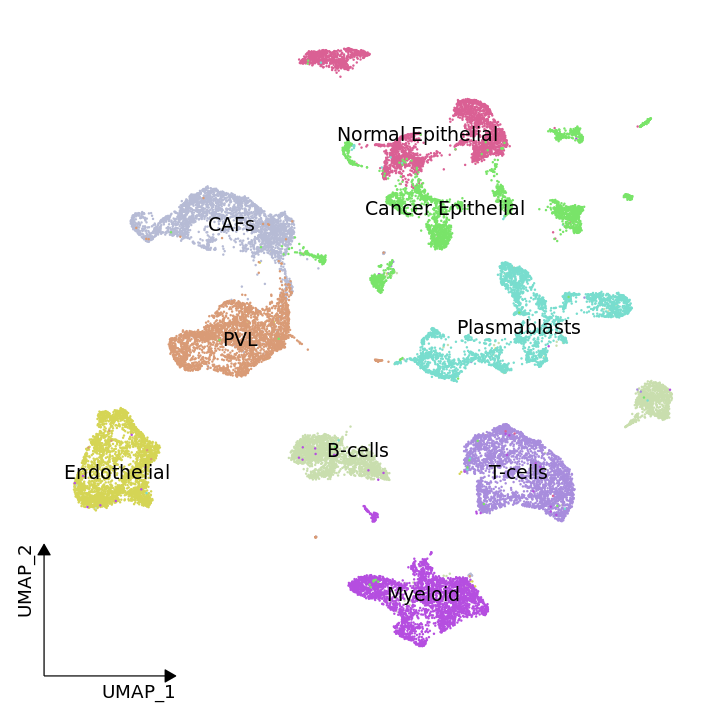

In [50]:
options(repr.plot.width = 6, repr.plot.height = 6)
DimPlot(brain.sc, label = TRUE, cols = cell.colors) + theme_dr(xlength = 0.2, ylength = 0.2, arrow = grid::arrow(length = unit(0.1, "inches"), ends = 'last', type = "closed")) + theme(panel.grid = element_blank()) + NoLegend()
ggsave(file.path(out.figs.dir, 'thymus.SC.cluster.UMAP.dimplot.pdf'), width = 6, height = 6)

In [51]:
levels(brain.sc) %>% length

[1] 9

In [52]:
#markers <- FindAllMarkers(brain.st, only.pos = TRUE, logfc.threshold = 0.25, min.pct = 0.25, assay = 'SCT')

In [53]:
#openxlsx::write.xlsx(markers, file = file.path(out.data.dir, 'Thymus.ST.markers.xlsx'))

In [54]:
#top20.markers <- markers %>% group_by(cluster) %>% top_n(n = 50, wt = avg_log2FC)

In [55]:
#saveRDS(brain.sc, file = file.path(out.data.dir, 'brain.sc.RDS'))
#saveRDS(brain.st, file = file.path(out.data.dir, 'brain.st.RDS'))

### Showing the projection performance for Cell2Spatial

In [287]:
cell2spatial <- readRDS('../2.results/BRCA/data/BRCA.2.cell2spatial.RDS')$obj

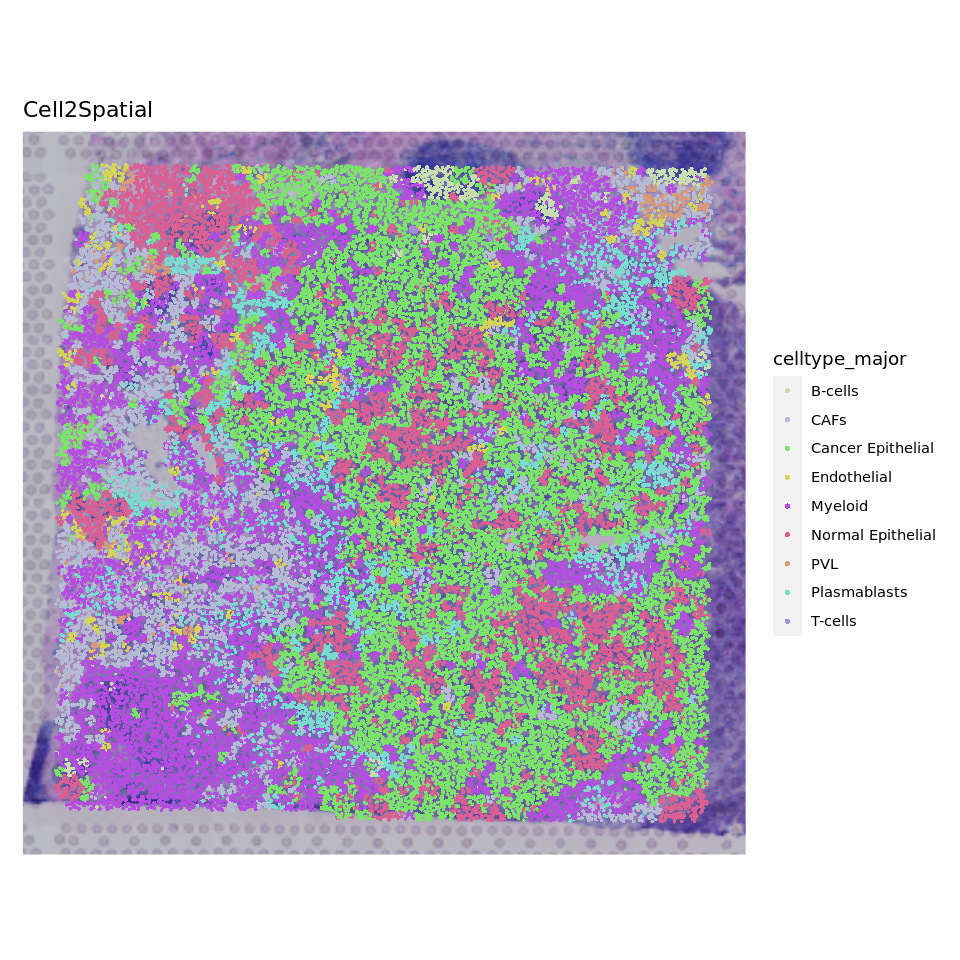

In [288]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cell2spatial, group.by = 'celltype_major', pt.size = 1.0, image.alpha = 1, stroke = 0, cols = cell.colors) + ggtitle('Cell2Spatial')
ggsave(file.path(out.figs.dir, 'cell2spatial.entire.UMAP.pdf'), width = 8, height = 6)

In [62]:
length(cell2spatial$celltype_major %>% unique)

[1] 9

In [63]:
f.ctypes <- cell2spatial$celltype_major %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cell2spatial, celltype_major == ct) %>% Cells
    obj.sub <- cell2spatial[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'celltype_major',  pt.size.factor = 1.6, crop = FALSE, stroke = 0, cols = cell.colors[ct]) + ggtitle(ct) + NoLegend()  
})

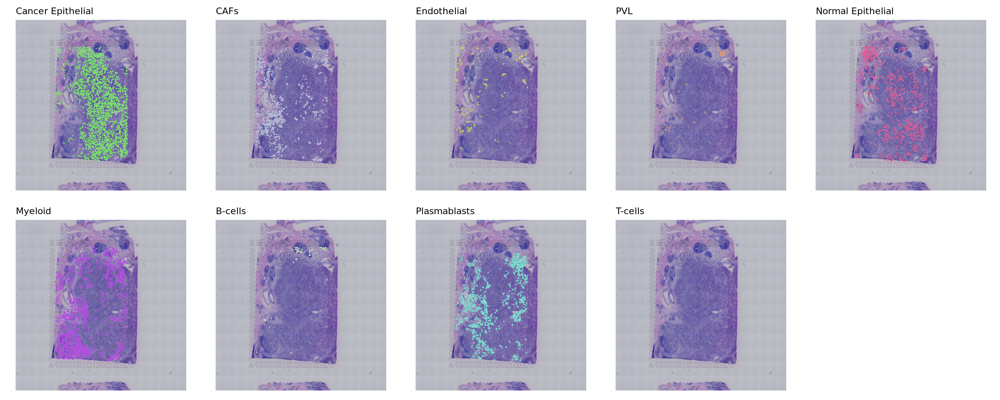

In [64]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'cell2spatial.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for CytoSpace

In [65]:
cytospace <- forCytoSpace('../2.results/BRCA/data/cytospace.2/', brain.sc, brain.st)

In [66]:
head(cytospace@meta.data)

,orig.ident,nCount_Spatial,nFeature_Spatial,UniqueCID,OriginalCID,CellType,SpotID,row,col,x.new,y.new
,<fct>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
UCID00000,Cell2Spatial,2833,682,UCID00000,CID3946_ATCCACCCAGGTCCCA,Endothelial,AGTCTGGACATCCTTG-1,126.74878,181.6656,128.27119,182.5410
UCID00001,Cell2Spatial,3579,886,UCID00001,CID4066_TATCAGGCAGACGCAA,Endothelial,GTATTCTGAGAAACGA-1,229.84221,216.4341,228.14685,215.5477
UCID00002,Cell2Spatial,3456,947,UCID00002,CID4465_ATTACTCAGTTACGGG,Endothelial,GCAAATATTACGCTTT-1,185.31705,222.6547,186.71796,223.3505
UCID00003,Cell2Spatial,4327,1823,UCID00003,CID4471_GTCTTCGGTAGAGGAA,Endothelial,GGAGACATTCACGGGC-1,81.97826,152.4103,80.84173,151.6740
UCID00004,Cell2Spatial,3523,1055,UCID00004,CID4530N_AAGCCGCAGAACTGTA,Endothelial,GCTAAGTAGTTTCTCT-1,182.41606,299.5237,181.25517,300.0764
UCID00005,Cell2Spatial,4640,2074,UCID00005,CID4471_GTCCTCAGTGCAGACA,Endothelial,CAGTCTCTCGGCTAAT-1,85.71635,197.7148,84.37876,197.3466


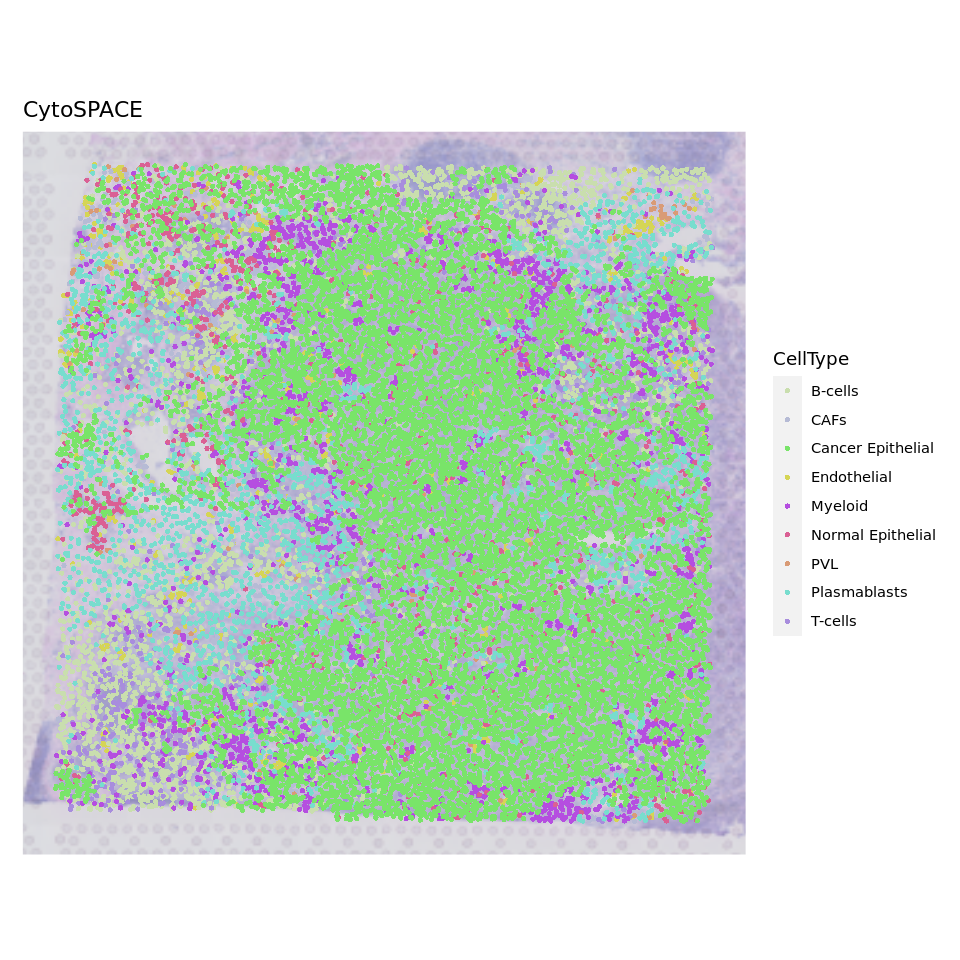

In [67]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cytospace, group.by = 'CellType', pt.size = 1.4, image.alpha = 0.5, cols = cell.colors, stroke = 0) + ggtitle('CytoSPACE')
ggsave(file.path(out.figs.dir, 'cytospace.entire.UMAP.pdf'), width = 8, height = 6)

In [68]:
length(cytospace$CellType %>% unique)

[1] 9

In [69]:
f.ctypes <- cytospace$CellType %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cytospace, CellType == ct) %>% Cells
    obj.sub <- cytospace[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'CellType', cols = cell.colors[ct], pt.size.factor = 1.2, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

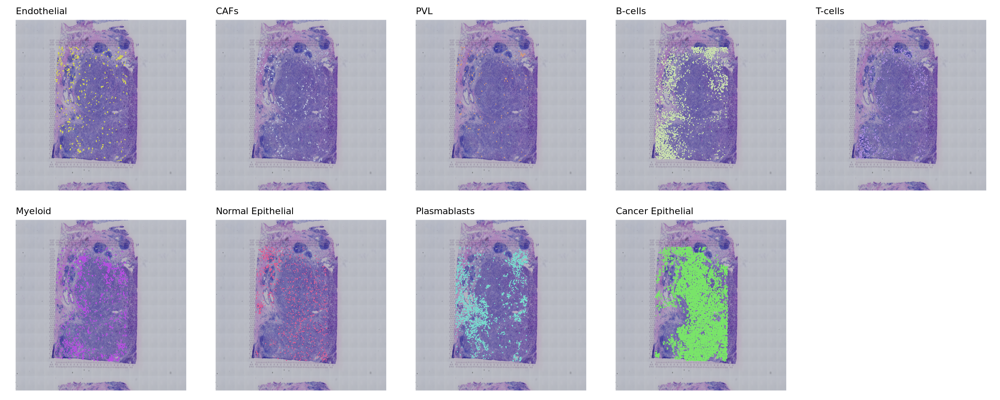

In [70]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'cytospace.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'cytospace.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for tangram

In [208]:
tangram <- forTangram('../2.results/BRCA/data/BRCA.2_tangram.xls', brain.sc, brain.st)

In [72]:
tangram@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,X.1,nCount_RNA,nFeature_RNA,X,percent.mito,subtype,celltype_subset,celltype_minor,celltype_major,SpotID,row,col,x.new,y.new
,<chr>,<dbl>,<int>,<chr>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
CID4471_CCGGTAGAGATTACCC,CID4471,4140,1760,CID4471_CCGGTAGAGATTACCC,4143,1760,CID4471_CCGGTAGAGATTACCC,7.289404,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,GACGACTTTCCAAGAA-1,68.33927,164.3318,69.21583,164.8358
CID3921_GGCAATTGTGATGTGG,CID3921,4365,1654,CID3921_GGCAATTGTGATGTGG,20181,4146,CID3921_GGCAATTGTGATGTGG,6.516030,HER2+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,AGGCAAAGAGGAATCA-1,68.71452,219.5083,67.99702,219.1332
CID44041_GTCAAGTAGGGTGTTG,CID44041,3553,864,CID44041_GTCAAGTAGGGTGTTG,1675,853,CID44041_GTCAAGTAGGGTGTTG,4.059701,TNBC,Endothelial ACKR1,Endothelial ACKR1,Endothelial,TGCAATCTAACACGGT-1,278.55289,318.5750,279.53454,319.0626
CID4530N_GCGCCAAGTCAGGACA,CID4530N,4816,2343,CID4530N_GCGCCAAGTCAGGACA,10408,3234,CID4530N_GCGCCAAGTCAGGACA,5.130669,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,TTGGACATGTGGCTTA-1,205.72502,198.8550,204.10120,197.8031
CID4290A_GTCAAGTGTTAAGATG,CID4290A,3526,1241,CID4290A_GTCAAGTGTTAAGATG,2481,1240,CID4290A_GTCAAGTGTTAAGATG,9.633212,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,GGTGAAACCGGGAATG-1,85.97614,237.1163,84.81525,237.6690
CID4471_CCCAGTTGTTGCGCAC,CID4471,4700,2100,CID4471_CCCAGTTGTTGCGCAC,6254,2100,CID4471_CCCAGTTGTTGCGCAC,5.052766,ER+,Endothelial RGS5,Endothelial RGS5,Endothelial,CATCCCGAGATTCATA-1,302.88657,367.6609,301.13492,367.1788


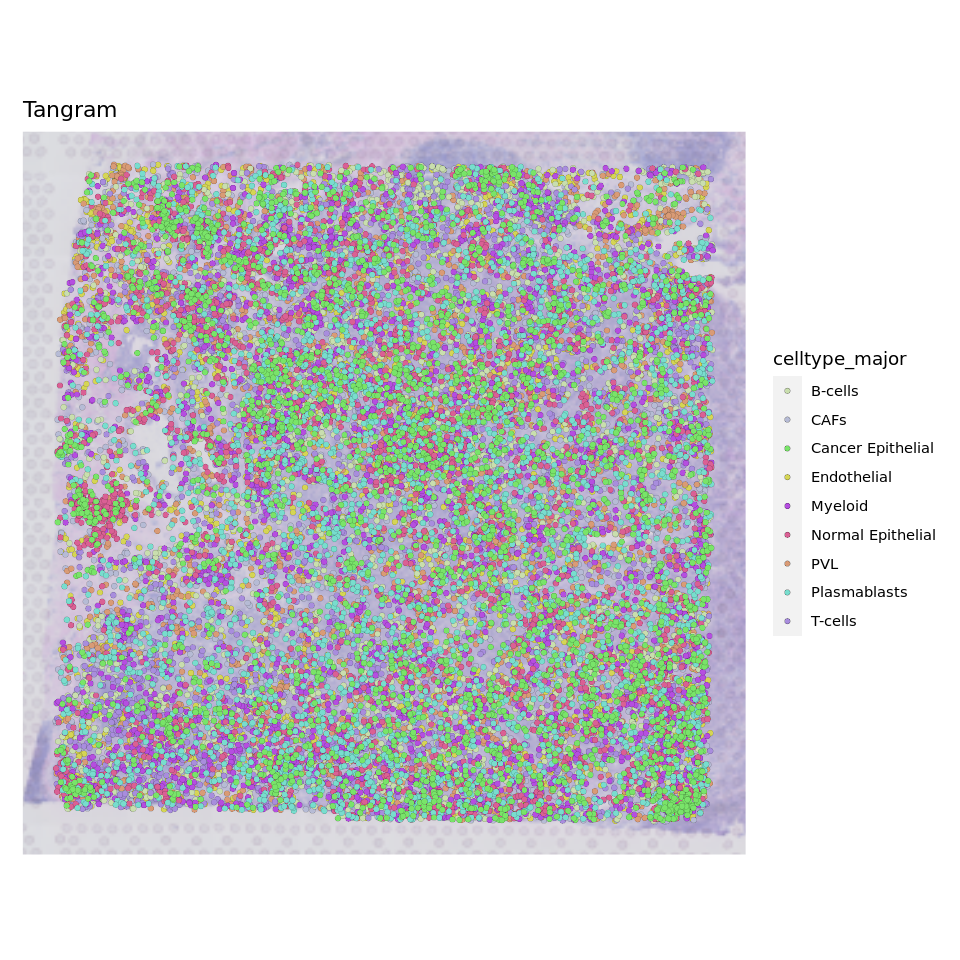

In [73]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(tangram, group.by = 'celltype_major', pt.size = 1.6, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('Tangram')
ggsave(file.path(out.figs.dir, 'tangram.entire.UMAP.pdf'), width = 8, height = 6)

In [74]:
length(f.ctypes <- tangram$celltype_major %>% unique)

[1] 9

In [75]:
f.ctypes <- tangram$celltype_major %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(tangram, celltype_major == ct) %>% Cells
    obj.sub <- tangram[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 0.5, group.by = 'celltype_major', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

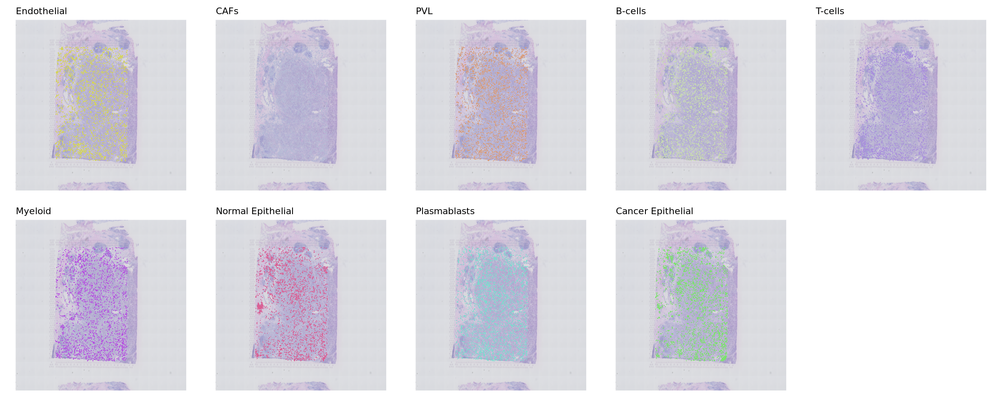

In [76]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'tangram.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'tangram.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for Celltrek

In [77]:
cell.trek <- readRDS('../2.results/BRCA/data/BRCA.2.celltrek.RDS') %>% { forCellTrek(list(xx = .), brain.sc, brain.st) }

In [209]:
cell.trek <- readRDS(file.path(out.data.dir, 'celltrek.reformat.RDS'))

In [89]:
saveRDS(cell.trek, file = file.path(out.data.dir, 'celltrek.reformat.RDS'))
cell.trek@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,nCount_RNA,nFeature_RNA,X,percent.mito,subtype,celltype_subset,celltype_minor,celltype_major,id_raw,id_new,coord_x,coord_y,Spot,centerX,centerY,imagerow,imagecol
,<chr>,<dbl>,<int>,<dbl>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
CID4471_GATCGTATCTTGTTTG,CID4471,3528,1135,2483,1135,CID4471_GATCGTATCTTGTTTG,8.618607,ER+,Endothelial ACKR1,Endothelial ACKR1,Endothelial,CID4471_GATCGTATCTTGTTTG,CID4471_GATCGTATCTTGTTTG,4717.800,10543.97,TGTTGGCTGGCGGAAG-1,68.25267,152.5113,68.09102,152.1789
CID3921_CGCGTTTAGCGATCCC,CID3921,4832,2285,7294,2336,CID3921_CGCGTTTAGCGATCCC,5.552509,HER2+,PVL Differentiated s3,PVL Differentiated,PVL,CID3921_CGCGTTTAGCGATCCC,CID3921_CGCGTTTAGCGATCCC,4737.735,10578.65,TGTTGGCTGGCGGAAG-1,68.25267,152.5113,68.37875,152.6794
CID4471_TCAACGACAATAACGA,CID4471,3552,1041,2229,1041,CID4471_TCAACGACAATAACGA,13.683266,ER+,PVL Differentiated s3,PVL Differentiated,PVL,CID4471_TCAACGACAATAACGA,CID4471_TCAACGACAATAACGA,4465.784,10673.59,GCATCCTCTCCTATTA-1,64.84653,154.5030,64.45373,154.0496
CID4471_GGTATTGGTAGCTCCG,CID4471,3538,1106,2260,1106,CID4471_GGTATTGGTAGCTCCG,6.858407,ER+,PVL Differentiated s3,PVL Differentiated,PVL,CID4471_GGTATTGGTAGCTCCG,CID4471_GGTATTGGTAGCTCCG,4534.743,10716.64,GCATCCTCTCCTATTA-1,64.84653,154.5030,65.44900,154.6711
CID4067_CGATCGGAGCAGCCTC,CID4067,3607,1040,2485,1040,CID4067_CGATCGGAGCAGCCTC,4.507042,ER+,PVL Differentiated s3,PVL Differentiated,PVL,CID4067_CGATCGGAGCAGCCTC,CID4067_CGATCGGAGCAGCCTC,4463.575,10736.51,GCATCCTCTCCTATTA-1,64.84653,154.5030,64.42185,154.9577
CID4471_AGCGTATAGTTAGCGG,CID4471,3593,1064,2564,1063,CID4471_AGCGTATAGTTAGCGG,9.477379,ER+,PVL Differentiated s3,PVL Differentiated,PVL,CID4471_AGCGTATAGTTAGCGG,CID4471_AGCGTATAGTTAGCGG,4519.103,10679.18,GCATCCTCTCCTATTA-1,64.84653,154.5030,65.22327,154.1304


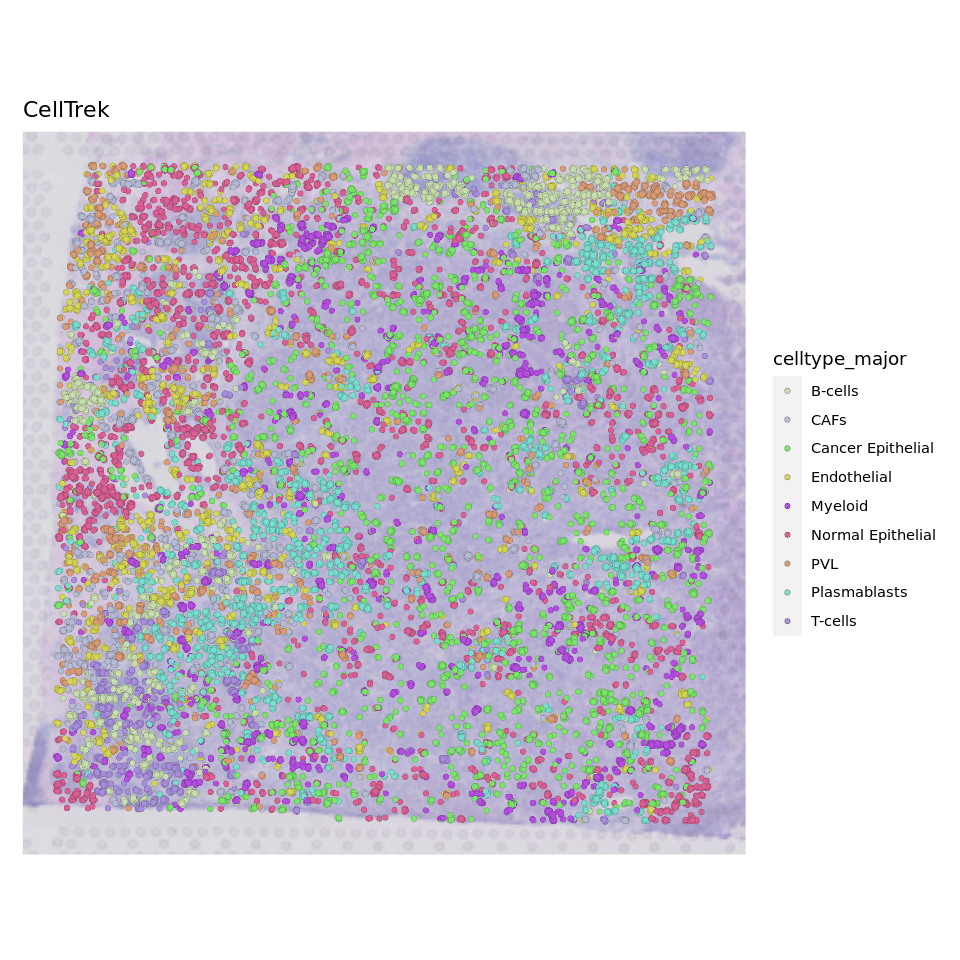

In [79]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(cell.trek, group.by = 'celltype_major', pt.size = 1.6, image.alpha = 0.5, cols = cell.colors, stroke = 0.1) + ggtitle('CellTrek')
ggsave(file.path(out.figs.dir, 'celltrek.entire.UMAP.pdf'), width = 8, height = 6)

In [80]:
length(f.ctypes <- cell.trek$celltype_major %>% unique)

[1] 9

In [81]:
f.ctypes <- cell.trek$celltype_major %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(cell.trek, celltype_major == ct) %>% Cells
    obj.sub <- cell.trek[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'celltype_major', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

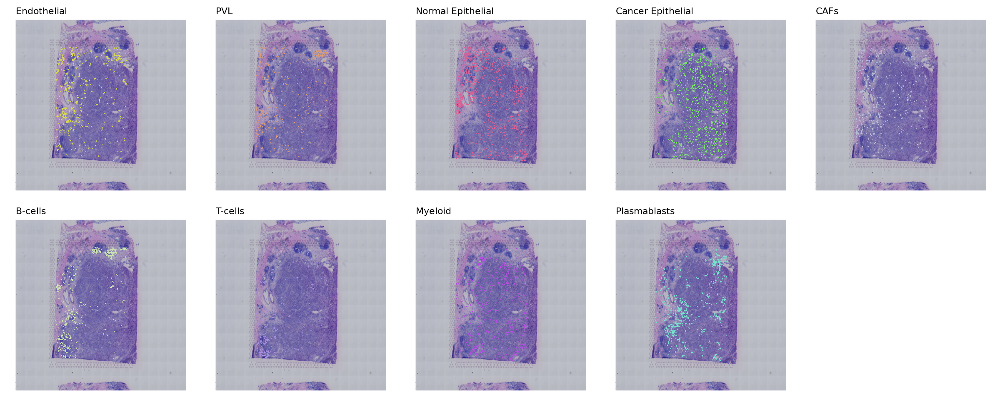

In [82]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'celltrek.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'celltrek.split.UMAP.eps'), width = 20, height = 8)

### Showing the projection performance for Seurat

In [210]:
seurat.res <- readRDS('../2.results/BRCA/data/BRCA.2.seurat.RDS') 

In [84]:
seurat.res@meta.data %>% head

,orig.ident,nCount_Spatial,nFeature_Spatial,X,nCount_RNA,nFeature_RNA,patientid,subtype,Classification,nCount_SCT,⋯,prediction.score.Endothelial,prediction.score.CAFs,prediction.score.PVL,prediction.score.B.cells,prediction.score.T.cells,prediction.score.Myeloid,prediction.score.Normal.Epithelial,prediction.score.Plasmablasts,prediction.score.Cancer.Epithelial,prediction.score.max
,<fct>,<dbl>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TGTTGGCTGGCGGAAG-1,BRCA,3566,1366,TGTTGGCTGGCGGAAG-1,3685,1441,1160920F,TNBC,Adipose tissue,10294,⋯,0.3070205,0.000000,0.00000000,0.10435056,0.002744519,0.15206624,0,0.13945620,0.29436198,0.3070205
GCATCCTCTCCTATTA-1,BRCA,4361,1726,GCATCCTCTCCTATTA-1,4526,1829,1160920F,TNBC,Adipose tissue,10395,⋯,0.3149007,0.000000,0.00000000,0.07243230,0.000000000,0.06541452,0,0.10441561,0.44283688,0.4428369
GCGAGGGACTGCTAGA-1,BRCA,4037,1577,GCGAGGGACTGCTAGA-1,4171,1668,1160920F,TNBC,Adipose tissue,10365,⋯,0.3714365,0.000000,0.00000000,0.14508171,0.002537577,0.05394588,0,0.16873298,0.25826531,0.3714365
TGGTACCGGCACAGCC-1,BRCA,4579,1754,TGGTACCGGCACAGCC-1,4722,1837,1160920F,TNBC,Adipose tissue,10407,⋯,0.7646625,0.000000,0.09004482,0.01828939,0.000000000,0.03107098,0,0.06604926,0.02988309,0.7646625
GCGCGTTTAAATCGTA-1,BRCA,5357,2103,GCGCGTTTAAATCGTA-1,5547,2217,1160920F,TNBC,Adipose tissue,10223,⋯,0.8134062,0.000000,0.18659378,0.00000000,0.000000000,0.00000000,0,0.00000000,0.00000000,0.8134062
TGCCTTGCCCTTACGG-1,BRCA,6560,2463,TGCCTTGCCCTTACGG-1,6810,2616,1160920F,TNBC,Adipose tissue,10058,⋯,0.8367668,0.026585,0.13664822,0.00000000,0.000000000,0.00000000,0,0.00000000,0.00000000,0.8367668


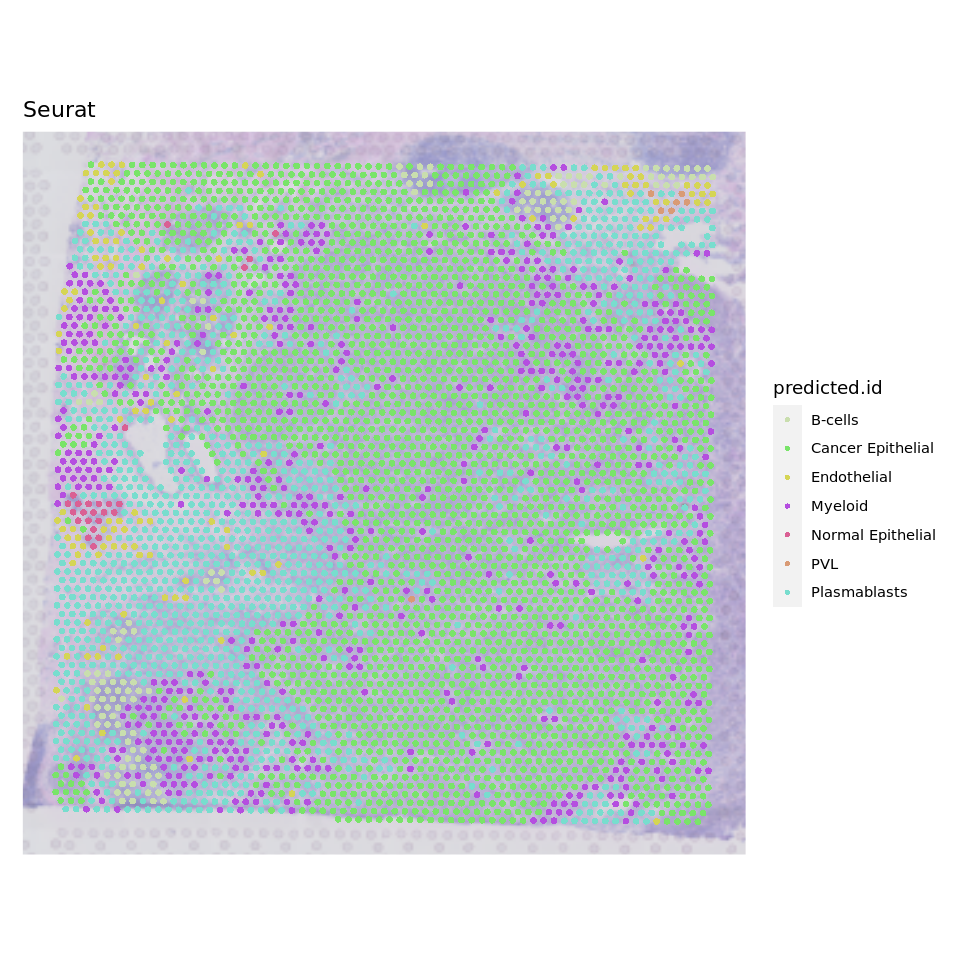

In [85]:
options(repr.plot.width = 8, repr.plot.height = 8)
SpatialPlot(seurat.res, group.by = 'predicted.id', pt.size = 1.8, image.alpha = 0.5, cols = cell.colors, stroke = 0) + ggtitle('Seurat')
ggsave(file.path(out.figs.dir, 'seurat.entire.UMAP.pdf'), width = 8, height = 6)

In [86]:
length(f.ctypes <- seurat.res$predicted.id %>% unique)

[1] 7

In [87]:
f.ctypes <- seurat.res$predicted.id %>% unique
gps <- lapply(f.ctypes, function(ct) {
    h.cells <- subset(seurat.res, predicted.id == ct) %>% Cells
    obj.sub <- seurat.res[, h.cells]
    SpatialDimPlot(obj.sub, image.alpha = 1, group.by = 'predicted.id', cols = cell.colors[ct], pt.size.factor = 1, crop = FALSE, stroke = 0) + ggtitle(ct) + NoLegend()  
})

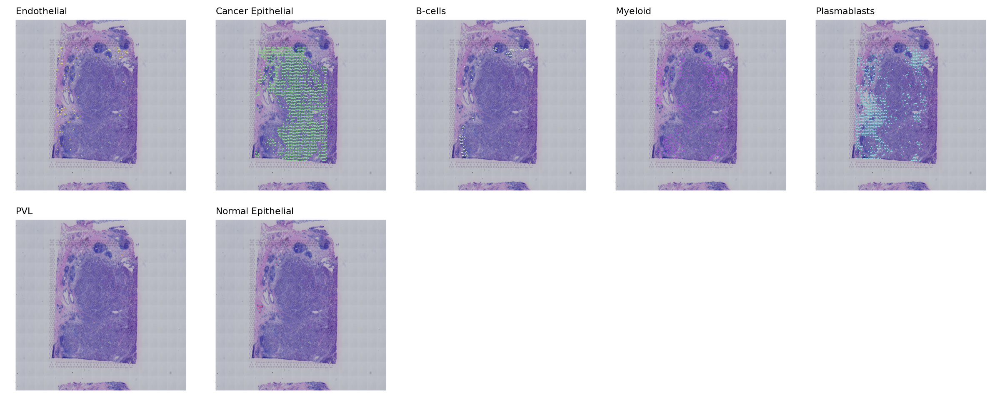

In [88]:
options(repr.plot.width = 20, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 5)
ggsave(file.path(out.figs.dir, 'seurat.split.UMAP.pdf'), width = 20, height = 8)
ggsave(file.path(out.figs.dir, 'seurat.split.UMAP.eps'), width = 20, height = 8)

### Comparison of the performace based on cellular compositions, take CARD deconvolution results as standard

In [226]:
brain.sc$CellTypeNew <- factor(brain.sc$celltype_major, levels = unique(brain.sc$celltype_major))

In [211]:
card.res <- readRDS('../2.results/BRCA/data/BRCA.2.card.RDS')$decon

In [296]:
prop.card <- card.res@Proportion_CARD * 10
prop.card[prop.card < 1] <- 0
prop.card <- apply(prop.card, 1, ceiling) %>% t

In [297]:
prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.card <- colSums(prop.card) / sum(prop.card) * 100
prop.card <- prop.card[names(prop)]

In [334]:
prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.cell2spatial <- cell2spatial$celltype_major %>% table %>% {./sum(.)} * 100
prop[names(prop.cell2spatial)] <- prop.cell2spatial
prop.cell2spatial <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.cytospace <- cytospace$CellType %>% table %>% {./sum(.)} * 100
prop[names(prop.cytospace)] <- prop.cytospace
prop.cytospace <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.cell.trek <- cell.trek$celltype_major %>% table %>% {./sum(.)} * 100
prop[names(prop.cell.trek)] <- prop.cell.trek
prop.cell.trek <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.tangram <- tangram$celltype_major %>% table %>% {./sum(.)} * 100
prop[intersect(names(prop.tangram), names(prop))] <- prop.tangram[intersect(names(prop.tangram), names(prop))]
prop.tangram <- prop

prop <- rep(0, length(levels(brain.sc$CellTypeNew))) %>% `names<-`(levels(brain.sc$CellTypeNew))
prop.seurat <- seurat.res$predicted.id %>% table %>% {./sum(.)} * 100
prop[names(prop.seurat)] <- prop.seurat
prop.seurat <- prop

In [335]:
prop.df <- cbind.data.frame(CARD = prop.card, Cell2Spatial = prop.cell2spatial, CytoSPACE = prop.cytospace, CellTrek = prop.cell.trek, Tangram = prop.tangram, Seurat = prop.seurat)

In [336]:
openxlsx::write.xlsx(prop.df, file = file.path(out.data.dir, 'methods.corr.vs.card.xlsx'))

In [337]:
prop.df$CellType <- rownames(prop.df)
gps <- lapply(colnames(prop.df)[2 : (ncol(prop.df) - 1)], function(meth) {
    plot.df.sub <- prop.df[, c('CARD', meth, 'CellType')] %>% `colnames<-`(c('CARD', 'Y', 'CellType'))
    ggplot(plot.df.sub, aes(x = CARD, y = Y)) + geom_point(size = 4, aes(color = CellType)) + theme_classic() + 
        geom_smooth(method = lm, se = TRUE) + ylab(meth) + ggpubr::stat_cor() + scale_color_manual(values = cell.colors)
})

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


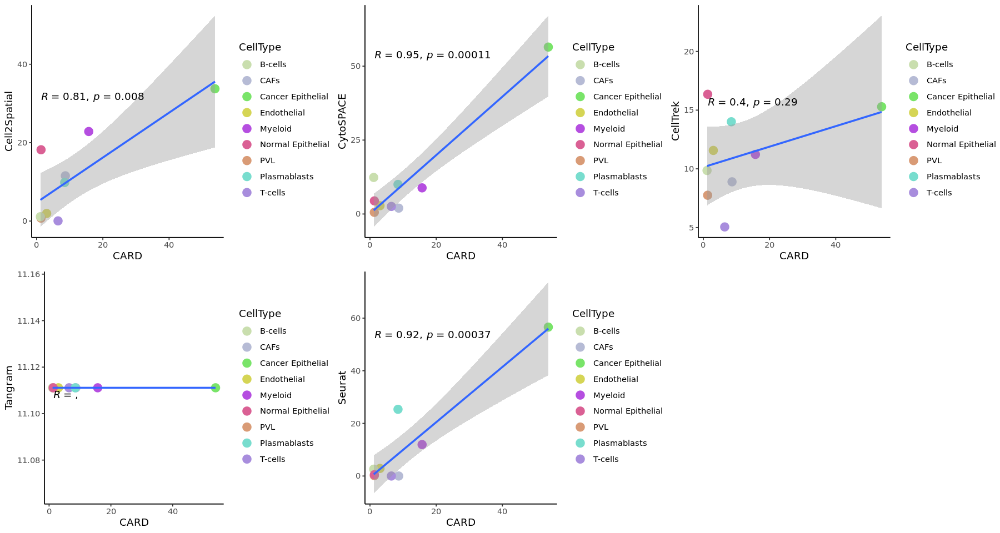

In [338]:
options(repr.plot.width = 15, repr.plot.height = 8)
ggarrange(plotlist = gps, nrow = 2, ncol = 3)
ggsave(file.path(out.figs.dir, 'methods.corr.vs.card.pdf'), width = 15, height = 8)

In [341]:
prop.df

,CARD,Cell2Spatial,CytoSPACE,CellTrek,Tangram,Seurat,CellType
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Endothelial,3.025292,1.94484168,2.7996540,11.568123,11.11111,2.8804903,Endothelial
CAFs,8.673069,11.54239019,1.9802431,8.894602,11.11111,0.0000000,CAFs
PVL,1.310183,0.74770174,0.5599308,7.750643,11.11111,0.1430031,PVL
B-cells,1.125739,1.10725230,12.3594483,9.858612,11.11111,2.5944842,B-cells
T-cells,6.463991,0.04085802,2.5583830,5.051414,11.11111,0.0000000,T-cells
Myeloid,15.739151,22.84371808,8.8405335,11.227506,11.11111,11.9509704,Myeloid
Normal Epithelial,1.331383,18.18998979,4.4339236,16.349614,11.11111,0.4902962,Normal Epithelial
Plasmablasts,8.467426,9.83452503,10.0059180,14.010283,11.11111,25.3524004,Plasmablasts
Cancer Epithelial,53.863766,33.74872319,56.4619657,15.289203,11.11111,56.5883555,Cancer Epithelial


### J-index analysis

In [90]:
markers.sc <- FindAllMarkers(brain.sc, only.pos = TRUE, logfc.threshold = 0.25, min.pct = 0.25, assay = 'SCT')

Calculating cluster Endothelial

Calculating cluster CAFs

Calculating cluster PVL

Calculating cluster B-cells

Calculating cluster T-cells

Calculating cluster Myeloid

Calculating cluster Normal Epithelial

Calculating cluster Plasmablasts

Calculating cluster Cancer Epithelial



In [91]:
top20.markers.sc <- markers.sc %>% group_by(cluster) %>% top_n(n = 30, wt = avg_log2FC)
marker.lust <- split(top20.markers.sc$gene, top20.markers.sc$cluster)

In [92]:
card.res <- readRDS('../2.results/BRCA/data/BRCA.2.card.RDS')$decon@Proportion_CARD[, names(marker.lust)]
ovp.spots <- intersect(rownames(card.res), colnames(brain.st))
brain.st <- brain.st[, ovp.spots]
card.res <- card.res[ovp.spots, ]
colnames(card.res) <- paste0('Cluster', 1 : ncol(card.res))
brain.st@meta.data <- cbind.data.frame(brain.st@meta.data, card.res)

In [93]:
avgDist <- function(obj, brain.st, ctype, p.cut = 0.05) {
    res <- lapply(1 : length(names(marker.lust)), function(idx) {
        cell.name <- names(marker.lust)[idx]
        scores <- brain.st@meta.data[, paste0('Cluster', idx)] %>% `names<-`(rownames(brain.st@meta.data))
        pvals <- pnorm(scores, mean = mean(scores), sd = sd(scores), lower.tail = FALSE)
        spots <- pvals[pvals < p.cut] %>% names
        if (length(spots) == 0) return(0)
        if (!(cell.name %in% unique(obj@meta.data[, ctype]))) return(0)
        if (sum(spots %in% obj$SpotName) == 0) return(0)
        #xx <- subset(obj, SpotName %in% spots)
        xx <- obj
        if (!(cell.name %in% unique(xx@meta.data[, ctype]))) return(0)
        xx <- table(xx$SpotName, xx@meta.data[, ctype])
        #pre <- colSums(xx > 0)[cell.name]
        pre <- rownames(xx)[which(xx[, cell.name] > 0)]
        length(intersect(spots, pre)) / length(union(spots, pre)) * 100
    }) %>% unlist(.) %>% as.vector #%>% mean
    mean(res) * sum(res > 0) / length(res)
}

In [1]:
p.cut <- 0.01

In [136]:
xx.1 <- avgDist(cell2spatial, brain.st, 'CellType', p.cut = p.cut)
print(xx.1)

[1] 17.47159


In [137]:
cytospace$SpotName <- cytospace$SpotID 
xx.2 <- avgDist(cytospace, brain.st, 'CellType', p.cut = p.cut)
print(xx.2)

[1] 17.0795


In [138]:
cell.trek$SpotName <- cell.trek$Spot 
xx.3 <- avgDist(cell.trek, brain.st, 'celltype_major', p.cut = p.cut)
print(xx.3)

[1] 18.24607


In [139]:
tangram$SpotName <- tangram$SpotID
xx.4 <- avgDist(tangram, brain.st, 'celltype_major', p.cut = p.cut)
print(xx.4)

[1] 6.160338


In [140]:
seurat.res$SpotName <- rownames(seurat.res@meta.data)
xx.5 <- avgDist(seurat.res, brain.st, 'predicted.id', p.cut = p.cut)
print(xx.5)

[1] 11.31227


In [158]:
plot.df <- cbind.data.frame(Index = c(xx.1, xx.2, xx.3, xx.4, xx.5), Method = c('Cell2Spatial', 'CytoSPACE', 'CellTrek', 'Tangram', 'Seurat'), Data = 'DLPFC')

In [159]:
openxlsx::write.xlsx(plot.df, file = file.path(out.data.dir, 'BRCA.2.acc.xlsx'))

### Number of cell types projected

In [339]:
number.cts <- c(
    Reference = length(cell.colors),
    Cell2Spatial = unique(cell2spatial$CellType) %>% length, 
    CytoSPACE = unique(cytospace$CellType) %>% length, 
    CellTrek = unique(cell.trek$celltype_major) %>% length, 
    Tangram = unique(tangram$celltype_major) %>% length, 
    Seurat = unique(seurat.res$predicted.id) %>% length    
)
number.cts

Reference Cell2Spatial    CytoSPACE     CellTrek      Tangram       Seurat 
           9            9            9            9            9            7

png 
  2

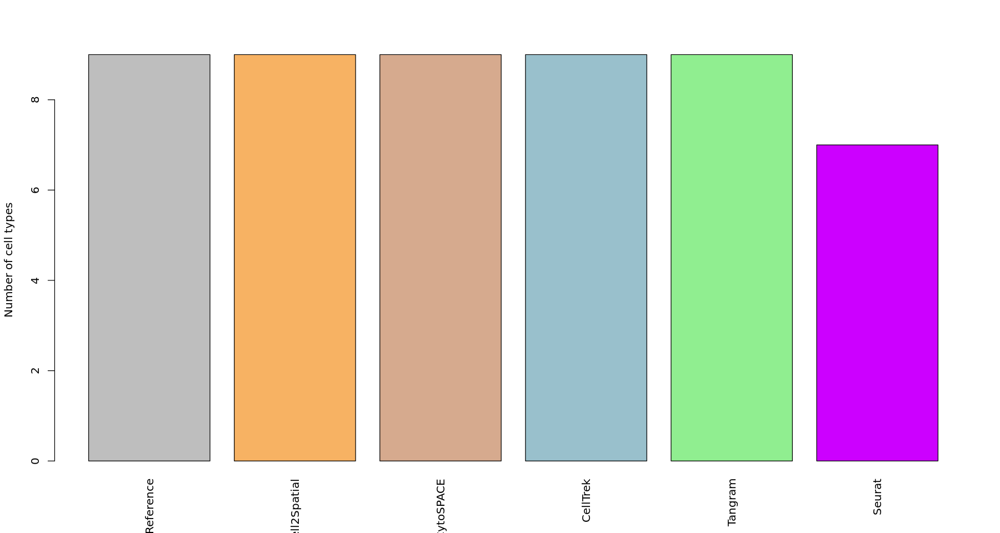

In [340]:
pdf(file.path(out.figs.dir, 'number.of.ctypes.pdf'), width = 6, height = 4)
bp <- barplot(number.cts, las = 3, ylab = 'Number of cell types', col = MTH_COLOR)
text(bp, 20, labels = round(number.cts, digits = 2))

dev.off()
barplot(number.cts, las = 3, ylab = 'Number of cell types', col = MTH_COLOR)

#### Compare with other tools using ST datasets

In [163]:
BRCA.2 <- openxlsx::read.xlsx('../2.results/BRCA.2/data/BRCA.2.acc.xlsx') %>% cbind.data.frame(., Data = 'BRCA.2') %>% .[, -3]
BRCA.2$Index <- BRCA.2$Index / max(BRCA.2$Index)
BRCA.2

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,0.9575534,Cell2Spatial,BRCA.2
2,0.9360645,CytoSPACE,BRCA.2
3,1.0000000,CellTrek,BRCA.2
4,0.3376254,Tangram,BRCA.2
5,0.6199839,Seurat,BRCA.2


In [164]:
BRCA.1 <- openxlsx::read.xlsx('../2.results/BRCA/data/BRCA.1.acc.xlsx') %>% .[, -3] %>% cbind.data.frame(., Data = 'BRCA.1')
BRCA.1$Index <- BRCA.1$Index / max(BRCA.1$Index)
BRCA.1

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,1.0000000,Cell2Spatial,BRCA.1
2,0.9702074,CytoSPACE,BRCA.1
3,0.9121642,CellTrek,BRCA.1
4,0.5092341,Tangram,BRCA.1
5,0.4732749,Seurat,BRCA.1


In [165]:
COVID19 <- openxlsx::read.xlsx('../2.results/COVID19/data/COVID19.acc.xlsx') %>% .[, -3] %>% cbind.data.frame(., Data = 'COVID19')
COVID19$Index <- COVID19$Index / max(COVID19$Index)
COVID19

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,1.0000000,Cell2Spatial,COVID19
2,0.9520850,CytoSPACE,COVID19
3,0.7373980,CellTrek,COVID19
4,0.8415089,Tangram,COVID19
5,0.3340295,Seurat,COVID19


In [166]:
DLPFC <- openxlsx::read.xlsx('../2.results/DLPFC/data/DLPFC.acc.xlsx') %>% .[, -3] %>% cbind.data.frame(., Data = 'DLPFC')

DLPFC$Index <- DLPFC$Index / max(DLPFC$Index)
DLPFC

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,1.0000000,Cell2Spatial,DLPFC
2,0.5128127,CytoSPACE,DLPFC
3,0.4015045,CellTrek,DLPFC
4,0.8114818,Tangram,DLPFC
5,0.4067113,Seurat,DLPFC


In [167]:
Mouse.Kidney <- openxlsx::read.xlsx('../2.results/Mouse.kidney/data/Mouse.1.acc.xlsx') %>% .[, -3]  %>% cbind.data.frame(., Data = 'Mouse.Kidney')

Mouse.Kidney$Index <- Mouse.Kidney$Index / max(Mouse.Kidney$Index)
Mouse.Kidney

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,1.0000000,Cell2Spatial,Mouse.Kidney
2,0.8540383,CytoSPACE,Mouse.Kidney
3,0.8200259,CellTrek,Mouse.Kidney
4,0.7709768,Tangram,Mouse.Kidney
5,0.3546944,Seurat,Mouse.Kidney


In [4]:
thymus <- openxlsx::read.xlsx('../2.results/Thymus/data/thymus.acc.xlsx') %>% .[, -3]  %>% cbind.data.frame(., Data = 'Thymus')

thymus$Index <- thymus$Index / max(thymus$Index)

In [199]:
intestinal <- openxlsx::read.xlsx('../2.results/Intestinal/data/intestinal.acc.xlsx')  %>% .[, -3] %>% cbind.data.frame(., Data = 'Intestinal')

intestinal$Index <- intestinal$Index / max(intestinal$Index)
intestinal

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,1.0000000,Cell2Spatial,Intestinal
2,0.9199958,CytoSPACE,Intestinal
3,0.7834614,CellTrek,Intestinal
4,0.7471925,Tangram,Intestinal
5,0.9788468,Seurat,Intestinal


In [200]:
plot.df <- rbind.data.frame(intestinal,thymus, Mouse.Kidney,DLPFC, COVID19, BRCA.1, BRCA.2)

In [201]:
openxlsx::write.xlsx(plot.df, file = file.path(out.data.dir, 'jcc.index.xlsx'))

In [202]:
head(plot.df)

,Index,Method,Data
,<dbl>,<chr>,<chr>
1,1.0000000,Cell2Spatial,Intestinal
2,0.9199958,CytoSPACE,Intestinal
3,0.7834614,CellTrek,Intestinal
4,0.7471925,Tangram,Intestinal
5,0.9788468,Seurat,Intestinal
6,0.9442201,Cell2Spatial,Thymus


In [203]:
MTH_COLOR

Reference Cell2Spatial    CytoSPACE     CellTrek      Tangram       Seurat 
      "grey"    "#F7B263"    "#D6AA8E"    "#99C0CC" "lightgreen"    "#CC00FF"

In [204]:
unique(plot.df$Data)

[1] "Intestinal"   "Thymus"       "Mouse.Kidney" "DLPFC"        "COVID19"     
[6] "BRCA.1"       "BRCA.2"

In [205]:
gps <- lapply(c('Thymus', 'Mouse.Kidney', 'DLPFC', 'COVID19', 'Intestinal', 'BRCA.1', 'BRCA.2'), function(xx) {
    sub.df <- subset(plot.df, Data == xx)
    order.index <- order(sub.df$Index) %>% rev
    sub.df$Method <- factor(sub.df$Method, levels = sub.df$Method[order.index])
    ggplot(sub.df, aes(x = Method, y = Index, fill = Method)) + geom_bar(stat="identity", ncol = 4) + theme_bw(base_size = 12) + 
    theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1))  + scale_fill_manual(values = MTH_COLOR[2:6]) + 
    ggtitle(xx)
})

In [2]:
options(repr.plot.width = 14, repr.plot.height = 5)

gp <- ggarrange(plotlist = gps, ncol = 4, nrow = 2)

ggsave(file.path(out.figs.dir, 'jcc.index.pdf'), width = 14, height = 5)